## Optional Tidy Bathy

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from mom6_forge.topo import Topo
from mom6_forge.grid import Grid
from mom6_forge.utils import compute_subsampling_factor
grid = Grid(
        resolution=1/12,
        xstart=261.5,   # 261.5° E / 98.5° W
        lenx=63,        # to ~35.5° W
        ystart=-6,      # 6° S
        leny=38,        # to 32° N
        name='carib_mom6_112_test_bathy'
    )
print("grid loaded")

# grid_check = Grid.from_supergrid('/glade/work/ajanney/MOM6_MPAS_CARIB/Variable_Res_Carib/rmom6_input/carib_mom6_1-12/ocnice/ocean_hgrid_carib_mom6_112_98cdf5.nc')

topo = Topo(grid = grid, min_depth = 5.0, git = False)
print("starting topo tidy")
# topo.tidy_dataset(output_dir = '/glade/work/ajanney/MOM6_MPAS_CARIB/Variable_Res_Carib/rmom6_input/carib_mom6_1-36/Test_bathy', positive_down=True)

grid loaded
starting topo tidy


In [ ]:
topo.set_from_dataset( # topo.mpi_set_from_dataset()
        bathymetry_path="/glade/work/ajanney/CrocoDashData/inputs/bathymetry/GEBCO_2024.nc",
        longitude_coordinate_name='lon',
        latitude_coordinate_name='lat',
        vertical_coordinate_name='elevation',
    )

Slicing source bathymetry to domain: (261.5, 324.5) x (-6.0, 32.0) with buffer 0.5
  Resolution Diagnostics

  Source dataset (GEBCO_2024.nc):
    dlon = 15.0 arcsec  (0.004167°)
    dlat = 15.0 arcsec  (0.004167°)
    dx   ~ 460 m)
    dy   ~ 463 m

  Model grid (T-cell spacing):
    median = 9.15 km
    min    = 8.54 km
    max    = 9.27 km

  Resolution ratio (model dx / dataset dx):
    median = 19.9x
    max    = 20.1x

  Cressman / stats-mask threshold: 12x
  → RECOMMENDED: high_res_regrid()  (Cressman + stats mask)
    Each model cell spans ~20 dataset pixels per side.
    Ocean-aware Cressman interpolation will meaningfully reduce
    land contamination of coastal depth estimates.
Masking depth threshold (mask_hmin) not provided in kwargs, defaulting to 0 m
Sub-sampling factors (nx_sub, ny_sub) not provided in kwargs, computing based on source dataset and model grid resolution
Resolution diagnostics recommend using stats-based masking, which we will set because no mask option w

/glade/u/home/manishrv/documents/croc/regional_mom_workflows/mom6_forge/mom6_forge/mapping.py:978: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  k: input_dataset.dims[k] for k in input_dataset.dims if k in src_spatial_dims
/glade/u/home/manishrv/documents/croc/regional_mom_workflows/mom6_forge/mom6_forge/mapping.py:995: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  k: output_dataset.dims[k] for k in output_dataset.dims if k in dst_spatial_dims


--- xESMF Regridding Info ---
  Source:        lat=9360, lon=15360  (143,769,600 points)  [287.74 MB]
  Destination:   ny=456, nx=333396  (152,028,576 points)  [2432.46 MB]
  Method:        nearest_s2d
  Weights:       generating new weights
  Periodic:      False
  Locstream out: False
-----------------------------


In [ ]:
# topo.set_depth_via_topog_file("/glade/work/ajanney/MOM6_MPAS_CARIB/Variable_Res_Carib/rmom6_input/carib_mom6_1-36/ocnice/ocean_topog_carib_mom6_136_2bb9f1.nc")

In [8]:
# Erase Pacific & Canada Bays
%matplotlib ipympl

from mom6_forge.topo_editor import TopoEditor
topo.depth["units"] = "m"
TopoEditor(topo)

TopoEditor(children=(VBox(children=(HTML(value='<h2>Topo Editor</h2>'), VBox(children=(VBox(children=(HTML(val…

### Optional change to ESMF mesh if land sea mask changes

In [24]:
INPUT_DIR = "/glade/work/ajanney/MOM6_MPAS_CARIB/Variable_Res_Carib/rmom6_input/carib_mom6_1-36/ocnice/"
topo.write_topo(INPUT_DIR + "ocean_topog_carib_mom6_136_2bb9f1.nc")
topo.write_esmf_mesh(INPUT_DIR + "ESMF_mesh_carib_mom6_136_2bb9f1.nc")

In [1]:
import xarray as xr

In [2]:
data = xr.open_dataset('/glade/work/ajanney/MOM6_MPAS_CARIB/Variable_Res_Carib/rmom6_input/carib_mom6_1-36/ocnice/ocean_topog_carib_mom6_136_2bb9f1.nc')

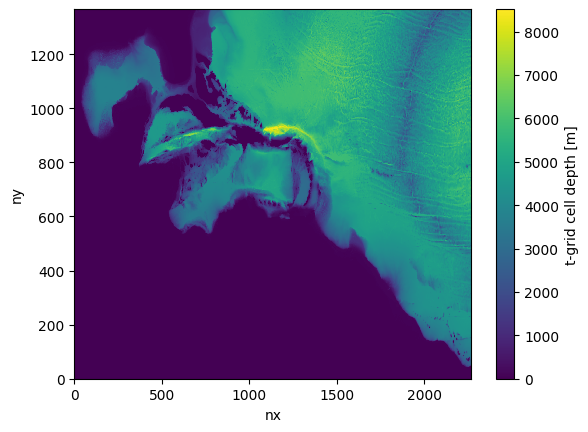

In [4]:
data['depth'].plot()